## 0. Configuration

In [ ]:
QUICK = False                         
RUN_S1, RUN_S2 = True, True           

SEEDS = [0] if QUICK else [0, 1, 2]   
K_FOLDS, SPLIT_SEED = 5, 0             

CFG = dict(
    backbone="vit_base_patch14_dinov2.lvd142m",   
    weights_file=None,        
    pretrained=True,
    cache_size=256, crop=224, lora_r=8,
    bs=16, eval_bs=64, lr_lora=5e-4, lr_head=1e-3, wd=1e-4,
    legacy_epochs=4 if QUICK else 20, legacy_patience=5,
    epochs=4 if QUICK else 30, patience=6,
    kd_lambda=1.0, fd_alpha=1.0, fd_beta=5.0,              
    wise_alpha=0.5, ct_eps=0.0,
    min_pos=5, n_boot=50 if QUICK else 300,               
    alphas=(0.05, 0.10), ltt_delta=0.10,                    
    s1_epochs=2 if QUICK else 15,                           
    shape_dup_thr=5,                                      
    s2_backbone="vit_large_patch16_224",                    
    s2_weights=str(config.RETFOUND_WEIGHTS),
    s2_epochs=2 if QUICK else 20, s2_bs=16, s2_grad_ckpt=True,   
)
BASES = ["FT", "FD", "WiSE", "OE"]        
S2_METHODS = ["New", "New-FD"]            
OURS1 = ["OE+CRC-L10", "OE+CRC-L5"]       
OURS2 = ["OE+CRC10", "OE+CRC5"]           
NI_MARGIN = 1.0                          
import numpy as _np; GRID = _np.linspace(-8, 8, 801)   



## 1. Setup

In [ ]:
import json, sys, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config, audit, cure, cv, crc, frontier, certify, backbones

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = config.OUTPUT_DIR
CACHE, CKPT, RES = OUT / "cache", OUT / "checkpoints", OUT / "results"
for d in (CACHE, CKPT, RES):
    d.mkdir(parents=True, exist_ok=True)
CV04 = RES / ("cv_quick" if QUICK else "cv")        
RAW = RES / ("cv07_quick" if QUICK else "cv07")     
S2DIR = RES / ("s2_07_quick" if QUICK else "s2_07") 
RAW8 = RES / ("cv08_quick" if QUICK else "cv08")    
RAW8.mkdir(parents=True, exist_ok=True)
assert (CV04 / "folds.csv").exists(), f"Run notebook 04 first: {CV04 / 'folds.csv'} not found"
missing07 = [p for p in [RAW / f"legacy__s{s}.npz" for s in SEEDS] + [S2DIR / f"legacy__s{s}.npz" for s in SEEDS] if not p.exists()]
assert not missing07, f"Run notebook 07 first: {missing07[0]} not found"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
print("torch", torch.__version__)

device: cuda NVIDIA GeForce RTX 4060
torch 2.11.0+cu128


## 2. Manifests and label spaces

In [4]:
M = config.MANIFEST_DIR
man1 = {s: pd.read_csv(M / f"rfmid1_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
man2 = {s: pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS}
space = json.load(open(M / "label_space.json"))

classes1 = space["rfmid1_classes"]                       # 45, legacy output order
new2 = space["new"]                                      # 12 RFMiD 2.0-only (2.0 column names)
UNION = classes1 + new2                                  # 57 = update model output space
N_OLD = len(classes1)
shared_map = space["shared_map"]                         # 1.0 name -> 2.0 column
SH = [UNION.index(c) for c in shared_map]                # union indices of shared classes
RT = [UNION.index(c) for c in space["retired"]]          # retired (1.0 only)
NW = list(range(N_OLD, len(UNION)))                      # new (2.0 only)
OLD = list(range(N_OLD))
print(f"union {len(UNION)} = shared {len(SH)} + retired {len(RT)} + new {len(NW)}")

union 57 = shared 38 + retired 7 + new 12


## 3. Pooled set, folds, RFMiD 1.0 val/test and the shape-fitting set (as notebook 07)

In [5]:
folds_df = pd.read_csv(CV04 / "folds.csv", dtype={"ID": str})
man2_all = pd.concat([pd.read_csv(M / f"rfmid2_{s}.csv", dtype={"ID": str}) for s in config.SPLITS], ignore_index=True)
pool = folds_df.merge(man2_all, on=["split", "ID"], how="left", validate="one_to_one")
folds, groups = pool["fold"].values, pool["group"].values

def label_arrays(man, dataset):
    n = len(man)
    Y = np.zeros((n, len(UNION)), dtype=np.float32)
    Mk = np.zeros_like(Y)
    if dataset == "rfmid1":
        Y[:, OLD] = man[classes1].values
        Mk[:, OLD] = 1
    else:
        for c1, c2 in shared_map.items():
            j = UNION.index(c1)
            Y[:, j], Mk[:, j] = man[c2].values, 1
        for c2 in new2:
            j = UNION.index(c2)
            Y[:, j], Mk[:, j] = man[c2].values, 1
    return Y, Mk

def load_split(man, dataset):
    paths = [CACHE / dataset / f"{s}_{i}.jpg" for s, i in zip(man["split"], man["ID"])]
    missing = [p for p in paths if not p.exists()]
    assert not missing, f"image cache incomplete (run notebook 02 first), e.g. {missing[0]}"
    Y, Mk = label_arrays(man, dataset)
    return {"X": cure.load_cache(paths), "Y": torch.from_numpy(Y), "M": torch.from_numpy(Mk)}

t0 = time.time()
P2 = load_split(pool, "rfmid2")
D1 = {s: load_split(man1[s], "rfmid1") for s in ("val", "test")}
Yp, Mp = P2["Y"].numpy(), P2["M"].numpy()
Y1t, M1t = D1["test"]["Y"].numpy(), D1["test"]["M"].numpy()
HR = UNION.index("HR") if "HR" in UNION else None
GROUPS = {"shared": SH, "new": NW, "all": SH + NW, "all_exHR": [c for c in SH + NW if c != HR]}
print(f"pooled RFMiD 2.0: {len(pool)} images in {K_FOLDS} folds; loaded in {time.time() - t0:.0f}s")

# Legacy-anchored shapes are fitted on RFMiD 1.0 val; drop its near-duplicates of pooled 2.0 images
fp1 = pd.read_csv(CACHE / "fingerprints_rfmid1.csv", dtype={"ID": str})
fp2 = pd.read_csv(CACHE / "fingerprints_rfmid2.csv", dtype={"ID": str})
v1val_fp = man1["val"][["split", "ID"]].merge(fp1, on=["split", "ID"], how="left")
pool_fp = pool[["split", "ID"]].merge(fp2, on=["split", "ID"], how="left")
assert v1val_fp["phash"].notna().all() and pool_fp["phash"].notna().all(), "fingerprints missing: rerun notebook 02"
dmin, _ = audit.hamming_min(v1val_fp["phash"], pool_fp["phash"])
KEEP1V = dmin > CFG["shape_dup_thr"]
Y1v, M1v = D1["val"]["Y"].numpy(), D1["val"]["M"].numpy()
print(f"RFMiD 1.0 val images for legacy-anchored shapes: {KEEP1V.sum()} of {len(KEEP1V)} "
      f"({(~KEEP1V).sum()} near-duplicates of pooled 2.0 images excluded)")

pooled RFMiD 2.0: 748 images in 5 folds; loaded in 3s
RFMiD 1.0 val images for legacy-anchored shapes: 631 of 640 (9 near-duplicates of pooled 2.0 images excluded)


## 4. Helpers and legacy models

In [6]:
def pad_union(l45):
    return np.concatenate([l45, np.zeros((len(l45), len(UNION) - N_OLD), dtype=l45.dtype)], 1)

def fresh_backbone():
    return cure.build_backbone(CFG["backbone"], CFG["pretrained"], CFG["crop"], CFG["lora_r"], CFG["weights_file"])

def raw_file(model, seed, fold):
    return RAW / f"{model}__s{seed}__f{fold}.npz"

def s2_file(model, seed):
    return S2DIR / f"{model}__s{seed}.npz"

def legacy_for_seed(seed):
    cure.set_seed(seed)
    net = cure.Net(fresh_backbone(), N_OLD)
    for n_, p in net.backbone.named_parameters():
        p.requires_grad = n_.endswith(".A") or n_.endswith(".B")
    ck = CKPT / f"legacy_seed{seed}{'_quick' if QUICK else ''}.pt"
    if ck.exists():
        net.load_trainable(torch.load(ck, map_location="cpu"))
        net.to(DEVICE)
        print(f"  legacy: loaded {ck.name}")
    else:
        print(f"  legacy checkpoint {ck.name} not found: training it on RFMiD 1.0 ...")
        tr1 = load_split(man1["train"], "rfmid1")
        cfg = dict(CFG, epochs=CFG["legacy_epochs"], patience=CFG["legacy_patience"])
        tr = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in tr1.items()}
        va = {k: (v[:, :N_OLD] if k != "X" else v) for k, v in D1["val"].items()}
        cure.train(net, None, "legacy", tr, va, {}, cfg, DEVICE, OLD)
        torch.save(net.trainable_state(), ck)
        del tr1, tr
    for p in net.parameters():
        p.requires_grad = False
    net.eval()
    P = lambda X: cure.predict(net, None, X, "legacy", {}, CFG, DEVICE)
    l_v1val = P(D1["val"]["X"])
    thr45 = cure.f1_thresholds(l_v1val, D1["val"]["Y"].numpy()[:, :N_OLD], D1["val"]["M"].numpy()[:, :N_OLD], np.full(N_OLD, 0.5))
    return {"net": net, "l_v1val": l_v1val, "l_pool": pad_union(P(P2["X"])),
            "l_v1test": pad_union(P(D1["test"]["X"])),
            "thr": np.concatenate([thr45, np.full(len(UNION) - N_OLD, 0.5)])}

def subset(idx):
    return {k: P2[k][idx] for k in ("X", "Y", "M")}

v1_ret = lambda l: cure.macro_ap(l, Y1t, M1t, OLD)

def summarise(rows, keys):
    df = pd.DataFrame(rows)
    mean = df.groupby("variant")[keys].mean()
    sd = df.groupby("variant")[keys].std()
    fmt = lambda m, s: "nan" if pd.isna(m) else (f"{m:.3f}" if pd.isna(s) else f"{m:.3f} ± {s:.3f}")
    table = pd.DataFrame({k: [fmt(m, s) for m, s in zip(mean[k], sd[k])] for k in keys}, index=mean.index)
    return mean, table

def validity_table(info, mean):
    v = info.groupby("variant").agg(alpha=("alpha", "first"), method=("method", "first"), mean_lam=("lam", "mean"),
                                    mean_n_cal=("n_cal", "mean"),
                                    infeasible_share=("feasible", lambda f: float(1 - np.mean(f))),
                                    runs_above_alpha=("test_risk", lambda r: float(np.mean(r > info.loc[r.index, "alpha"]))))
    v["pooled_img_risk"] = (mean["img_risk_%"] / 100).reindex(v.index)
    return v

def bootstrap(FS, curve_models, points, seeds, n_img, contrasts, n_boot, rs=0):
    """Gap vs envelope of every point, and paired NFR- differences (contrasts: name -> (a, b), a - b)."""
    est_g, est_x, est_y = certify.envelope_stats(FS, curve_models, points, seeds, GRID)
    rng = np.random.default_rng(rs)
    G, X = [], []
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, n_img, n_img), minlength=n_img).astype(float)
        g, x, _ = certify.envelope_stats(FS, curve_models, points, seeds, GRID, w)
        G.append(g)
        X.append(x)
    G, X = pd.DataFrame(G), pd.DataFrame(X)
    gap = {p: certify.ci(est_g[p], G[p]) for p in points}
    con = {k: certify.ci(est_x[a] - est_x[b], X[a] - X[b]) for k, (a, b) in contrasts.items()}
    return gap, con

KEYS = ["mAP_all", "NFR+_%", "NFR-_%", "NFR_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]
TAGS = [int(round(100 * a)) for a in CFG["alphas"]]

def fd_file(seed, fold):
    return RAW8 / f"FD__s{seed}__f{fold}.npz"

def load_raw(model, seed, fold):
    return np.load(fd_file(seed, fold) if model == "FD" else raw_file(model, seed, fold))

def bootstrap2(FS, curve_models, points, seeds, n_img, contrasts, n_boot, rs=0):
    """Gap vs envelope of every point, and paired differences a - b in NFR- and NFR+ (points)."""
    est_g, est_x, est_y = certify.envelope_stats(FS, curve_models, points, seeds, GRID)
    rng = np.random.default_rng(rs)
    G, X, Yb = [], [], []
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, n_img, n_img), minlength=n_img).astype(float)
        g, x, y = certify.envelope_stats(FS, curve_models, points, seeds, GRID, w)
        G.append(g)
        X.append(x)
        Yb.append(y)
    G, X, Yb = pd.DataFrame(G), pd.DataFrame(X), pd.DataFrame(Yb)
    gap = {p: certify.ci(est_g[p], G[p]) for p in points}
    cx = {k: certify.ci(est_x[a] - est_x[b], X[a] - X[b]) for k, (a, b) in contrasts.items()}
    cy = {k: certify.ci(est_y[a] - est_y[b], Yb[a] - Yb[b]) for k, (a, b) in contrasts.items()}
    return gap, cx, cy

def per_class_miss(VAR, LEG, names, Y, M, cls_idx, min_caught=5):
    """Per class: mean number of legacy-detected positives per seed, and % of them each variant misses."""
    rows = []
    for j, c in enumerate(cls_idx):
        rec = {"class": UNION[c]}
        for n in names:
            miss = tot = 0
            for s in SEEDS:
                L, T = VAR[(n, s)]
                Lo, to = LEG[s]
                caught = crc.legacy_caught(Lo, to, Y, M, cls_idx)[:, j]
                pred = L[:, c] >= cure.logit(T[:, c])
                miss += int((caught & ~pred).sum())
                tot += int(caught.sum())
            rec["n_caught"] = tot / len(SEEDS)
            rec[n] = 100 * miss / tot if tot else np.nan
        rows.append(rec)
    df = pd.DataFrame(rows)
    return df[df["n_caught"] >= min_caught].sort_values("n_caught", ascending=False).reset_index(drop=True)

def class_summary(df, base, ours):
    d = df[ours] - df[base]
    return {"n_classes": int(len(df)), "worst_class_miss_%": {base: round(float(df[base].max()), 1), ours: round(float(df[ours].max()), 1)},
            "classes_worse_by_>5pts": df.loc[d > 5, "class"].tolist(),
            "classes_better_by_>5pts": int((d < -5).sum())}

KEYS8 = ["mAP_shared", "mAP_all", "NFR+_%", "NFR-_%", "img_risk_%", f"regressed_classes_min{CFG['min_pos']}"]

## 5. Scenario 1 · Stage A: focal distillation with the fixed-epoch protocol


In [7]:
if RUN_S1:
    cfg1 = dict(CFG, epochs=CFG["s1_epochs"])
    for seed in SEEDS:
        if all(fd_file(seed, k).exists() for k in range(K_FOLDS)):
            print(f"seed {seed}: FD predictions already saved")
            continue
        print(f"\n=== seed {seed} ===")
        pack = legacy_for_seed(seed)
        legacy = pack["net"]
        ctx = {"shared_idx": SH, "retired_idx": RT, "old_idx": OLD,
               "thr_logit": torch.tensor(cure.logit(pack["thr"]), dtype=torch.float32, device=DEVICE)}
        for k in range(K_FOLDS):
            if fd_file(seed, k).exists():
                continue
            te = np.where(folds == k)[0]
            va = np.where(folds == (k + 1) % K_FOLDS)[0]
            tr = np.where((folds != k) & (folds != (k + 1) % K_FOLDS))[0]
            t0 = time.time()
            cure.set_seed(seed * 100 + k)
            net = cure.expand_from_legacy(legacy, len(UNION), N_OLD)
            cure.train(net, legacy, "FD", subset(tr), None, ctx, cfg1, DEVICE, SH + NW, log=lambda *a: None)
            P = lambda X: cure.predict(net, None, X, "FT", {}, CFG, DEVICE)
            np.savez(fd_file(seed, k), Lva=P(P2["X"][va]), Lte=P(P2["X"][te]), L1v=P(D1["val"]["X"]))
            print(f"  fold {k}: FD trained {CFG['s1_epochs']} epochs in {(time.time() - t0) / 60:.1f} min")
            del net
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        del pack, legacy


=== seed 0 ===
  legacy: loaded legacy_seed0.pt
  fold 0: FD trained 15 epochs in 1.2 min
  fold 1: FD trained 15 epochs in 1.2 min
  fold 2: FD trained 15 epochs in 1.3 min
  fold 3: FD trained 15 epochs in 1.3 min
  fold 4: FD trained 15 epochs in 1.2 min

=== seed 1 ===


  legacy: loaded legacy_seed1.pt
  fold 0: FD trained 15 epochs in 1.2 min
  fold 1: FD trained 15 epochs in 1.2 min
  fold 2: FD trained 15 epochs in 1.2 min
  fold 3: FD trained 15 epochs in 1.2 min
  fold 4: FD trained 15 epochs in 1.2 min

=== seed 2 ===
  legacy: loaded legacy_seed2.pt
  fold 0: FD trained 15 epochs in 1.2 min


c:\Users\Sajjad\Documents\Documents\paper-1\paper-1\src\cure.py:346: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


  fold 1: FD trained 15 epochs in 1.2 min
  fold 2: FD trained 15 epochs in 1.2 min
  fold 3: FD trained 15 epochs in 1.2 min
  fold 4: FD trained 15 epochs in 1.2 min


## 6. Scenario 1 · threshold variants



In [8]:
VAR1, INFO1, LEG1 = {}, [], {}
if RUN_S1:
    for seed in SEEDS:
        z = np.load(RAW / f"legacy__s{seed}.npz")
        L_old, thr_old, L1v_old = z["L"], z["thr"], z["L1v"]
        LEG1[seed] = (L_old, thr_old)
        VAR1[("Legacy", seed)] = (L_old, np.broadcast_to(thr_old, L_old.shape).copy())
        fallback = np.where(np.arange(len(UNION)) < N_OLD, thr_old, 0.5)
        caught_all = crc.legacy_caught(L_old, thr_old, Yp, Mp, SH)
        for m in BASES:
            acc = {}
            for k in range(K_FOLDS):
                r = load_raw(m, seed, k)
                te = np.where(folds == k)[0]
                va = np.where(folds == (k + 1) % K_FOLDS)[0]
                Lva, Lte, L1v = r["Lva"], r["Lte"], r["L1v"]
                Yv, Mv, lo_va = Yp[va], Mp[va], L_old[va]
                plain_full = cv.plain_thresholds(Lva, Yv, Mv, fallback)
                A, B = crc.split_halves(groups[va], seed * 1000 + k)        # same halves as notebooks 06 and 07
                fitA = lambda kind: certify.fit_shape(kind, Lva[A], Yv[A], Mv[A], lo_va[A], thr_old, SH, fallback, None, CFG["ct_eps"])
                def anchored(kind):
                    s = certify.fit_shape(kind, L1v[KEEP1V], Y1v[KEEP1V], M1v[KEEP1V], L1v_old[KEEP1V], thr_old, SH, fallback, None, CFG["ct_eps"])
                    t = plain_full.copy()
                    t[SH] = s[SH]
                    return t
                ct_L, un_L = anchored("ct"), anchored("uniform")
                leg = plain_full.copy()
                leg[SH] = thr_old[SH]
                ct_A, un_A = fitA("ct"), fitA("uniform")
                thr = {m: plain_full,
                       f"{m}+CT": cv.constrained_thresholds(Lva, Yv, Mv, lo_va, thr_old, SH, fallback, CFG["ct_eps"]),
                       f"{m}+CT-L": ct_L, f"{m}+F1-L": un_L, f"{m}+LEG": leg}
                cal = {"B": B, "full": np.arange(len(va))}
                caught_cal = {c: crc.legacy_caught(lo_va[i], thr_old, Yv[i], Mv[i], SH) for c, i in cal.items()}
                for a, tag in zip(CFG["alphas"], TAGS):
                    plan = [("CRC-L", ct_L, "full", "CRC"), ("CRCu-L", un_L, "full", "CRC"), ("CRCleg", leg, "full", "CRC"),
                            ("CRC-A", ct_A, "B", "CRC"), ("CRCu-A", un_A, "B", "CRC"),
                            ("LTT-L", ct_L, "full", "LTT"), ("LTTu-L", un_L, "full", "LTT")]
                    for short, base, c, meth in plan:
                        i = cal[c]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lva[i], base, caught_cal[c], SH, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lva[i], base, caught_cal[c], SH, a, CFG["ltt_delta"], GRID)
                        name = f"{m}+{short}{tag}"
                        thr[name] = crc.shift_thresholds(base, SH, lam)
                        risk = crc.image_losses(Lte, thr[name], caught_all[te], SH)
                        INFO1.append({"variant": name, "seed": seed, "fold": k, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
                for name, t in thr.items():
                    acc.setdefault(name, []).append((te, Lte, t))
            for name, parts in acc.items():
                L = np.zeros((len(pool), len(UNION)), np.float32)
                T = np.zeros_like(L)
                for te, Lte, t in parts:
                    L[te], T[te] = Lte, t[None, :]
                VAR1[(name, seed)] = (L, T)
    info1 = pd.DataFrame(INFO1)
    NAMES1 = sorted({n for n, _ in VAR1}, key=lambda n: (n != "Legacy", n.split("+")[0], n))
    print(f"scenario 1: {len(NAMES1)} variants")

scenario 1: 77 variants


## 7. Scenario 1 · results, validity, envelope, ablation contrasts and the main table

In [9]:
if RUN_S1:
    rows = []
    blocks = [np.where(folds == k)[0] for k in range(K_FOLDS)]
    for (name, seed), (L, T) in VAR1.items():
        L_old, thr_old = LEG1[seed]
        res = cv.pooled_metrics(L, T, L_old, thr_old, Yp, Mp, GROUPS, SH, CFG["min_pos"])
        res.pop("per_class_ap")
        res["NFR-_%"] = frontier.point(frontier.flip_sets(L, T, L_old, thr_old, Yp, Mp, SH))[0]
        res["img_risk_%"] = 100 * certify.pooled_image_risk(L, T, crc.legacy_caught(L_old, thr_old, Yp, Mp, SH), SH, blocks)
        rows.append(dict(res, variant=name, seed=seed))
    mean1, table1 = summarise(rows, KEYS8)
    sd1 = pd.DataFrame(rows).groupby("variant")[KEYS8].std().reindex(NAMES1)
    mean1, table1 = mean1.reindex(NAMES1), table1.reindex(NAMES1)
    table1.to_csv(RES / ("s1_08_table_quick.csv" if QUICK else "s1_08_table.csv"))
    display(table1)
    valid1 = validity_table(info1, mean1)
    display(valid1.round(3))

    CURVES1 = BASES
    POINTS1 = [n for n in NAMES1 if n != "Legacy"]          # bases included, so main-table contrasts can use them
    FS1 = {(n, s): frontier.flip_sets(*VAR1[(n, s)], LEG1[s][0], LEG1[s][1], Yp, Mp, SH)
           for n in POINTS1 for s in SEEDS}
    CON1 = {}
    for m in BASES:
        for tag in TAGS:
            CON1[f"{m}{tag}: CT vs F1 shape, anchored (CRC-L - CRCu-L)"] = (f"{m}+CRC-L{tag}", f"{m}+CRCu-L{tag}")
            CON1[f"{m}{tag}: CT shape vs legacy thresholds (CRC-L - CRCleg)"] = (f"{m}+CRC-L{tag}", f"{m}+CRCleg{tag}")
            CON1[f"{m}{tag}: method vs plain CRC (CRC-L - CRCu-A)"] = (f"{m}+CRC-L{tag}", f"{m}+CRCu-A{tag}")
            CON1[f"{m}{tag}: LTT, CT vs F1 shape (LTT-L - LTTu-L)"] = (f"{m}+LTT-L{tag}", f"{m}+LTTu-L{tag}")
    MAIN1 = ["FT", "FD", "WiSE", "OE", "FD+CT", "WiSE+CT", "OE+CT", "OE+CRCu-A10", "OE+CRCu-A5", "OE+LTT-L10"]
    for o in OURS1:
        for b in MAIN1:
            if b != o:
                CON1[f"MAIN {o} vs {b}"] = (o, b)
    t0 = time.time()
    gap1, cx1, cy1 = bootstrap2(FS1, CURVES1, POINTS1, SEEDS, len(pool), CON1, CFG["n_boot"], rs=0)
    print(f"scenario 1 bootstrap: {(time.time() - t0) / 60:.1f} min")
    display(pd.DataFrame({"d_NFR-": cx1, "d_NFR+": cy1}))

,mAP_shared,mAP_all,NFR+_%,NFR-_%,img_risk_%,regressed_classes_min5
variant,,,,,,
Legacy,0.183 ± 0.004,0.143 ± 0.003,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
FD,0.362 ± 0.004,0.359 ± 0.005,9.591 ± 1.172,6.208 ± 0.224,30.317 ± 0.764,0.333 ± 0.577
FD+CRC-A10,0.362 ± 0.004,0.359 ± 0.005,2.259 ± 0.266,42.339 ± 5.182,7.360 ± 1.552,0.333 ± 0.577
FD+CRC-A5,0.362 ± 0.004,0.359 ± 0.005,0.682 ± 0.322,69.599 ± 4.718,2.007 ± 0.723,0.333 ± 0.577
FD+CRC-L10,0.362 ± 0.004,0.359 ± 0.005,2.344 ± 0.322,15.203 ± 9.008,7.191 ± 0.997,0.333 ± 0.577
...,...,...,...,...,...,...
WiSE+LEG,0.329 ± 0.018,0.317 ± 0.013,4.177 ± 0.604,1.777 ± 0.523,13.001 ± 1.134,0.000 ± 0.000
WiSE+LTT-L10,0.329 ± 0.018,0.317 ± 0.013,0.938 ± 0.074,16.996 ± 3.857,2.790 ± 0.544,0.000 ± 0.000
WiSE+LTT-L5,0.329 ± 0.018,0.317 ± 0.013,0.341 ± 0.195,47.087 ± 15.595,0.999 ± 0.479,0.000 ± 0.000


,alpha,method,mean_lam,mean_n_cal,infeasible_share,runs_above_alpha,pooled_img_risk
variant,,,,,,,
FD+CRC-A10,0.10,CRC,2.029,21.733,0.000,0.400,0.074
FD+CRC-A5,0.05,CRC,4.917,21.733,0.333,0.200,0.020
FD+CRC-L10,0.10,CRC,-0.169,45.667,0.000,0.200,0.072
FD+CRC-L5,0.05,CRC,0.576,45.667,0.000,0.267,0.034
FD+CRCleg10,0.10,CRC,0.961,45.667,0.000,0.333,0.090
FD+CRCleg5,0.05,CRC,1.569,45.667,0.000,0.267,0.027
FD+CRCu-A10,0.10,CRC,3.404,21.733,0.000,0.333,0.063
FD+CRCu-A5,0.05,CRC,5.369,21.733,0.333,0.067,0.018
FD+CRCu-L10,0.10,CRC,0.847,45.667,0.000,0.533,0.104


scenario 1 bootstrap: 1.5 min


,d_NFR-,d_NFR+
"FT5: CT vs F1 shape, anchored (CRC-L - CRCu-L)","[-8.352, -9.159, -7.395]","[0.213, -0.215, 0.646]"
FT5: CT shape vs legacy thresholds (CRC-L - CRCleg),"[3.952, 3.336, 4.681]","[0.256, -0.295, 0.726]"
FT5: method vs plain CRC (CRC-L - CRCu-A),"[-25.26, -26.149, -24.418]","[0.895, 0.401, 1.435]"
"FT5: LTT, CT vs F1 shape (LTT-L - LTTu-L)","[-7.782, -8.602, -6.946]","[0.085, -0.24, 0.387]"
"FT10: CT vs F1 shape, anchored (CRC-L - CRCu-L)","[-6.8, -7.465, -6.077]","[-0.043, -0.899, 0.702]"
FT10: CT shape vs legacy thresholds (CRC-L - CRCleg),"[1.541, 1.228, 1.943]","[0.043, -0.712, 0.76]"
FT10: method vs plain CRC (CRC-L - CRCu-A),"[-27.661, -28.45, -26.869]","[1.279, 0.546, 2.046]"
"FT10: LTT, CT vs F1 shape (LTT-L - LTTu-L)","[-7.417, -8.427, -6.318]","[0.043, -0.307, 0.446]"
"FD5: CT vs F1 shape, anchored (CRC-L - CRCu-L)","[-10.41, -10.867, -9.911]","[-0.341, -0.832, 0.107]"
FD5: CT shape vs legacy thresholds (CRC-L - CRCleg),"[-0.633, -0.945, -0.384]","[0.384, -0.166, 0.952]"


## 8. Scenario 2 · threshold variants (model update, notebook 07's RETFound predictions)


In [10]:
VAR2, INFO2, LEG2 = {}, [], {}
if RUN_S2:
    Y1t45, M1t45 = Y1t[:, :N_OLD], M1t[:, :N_OLD]
    Y1v45, M1v45 = Y1v[:, :N_OLD], M1v[:, :N_OLD]
    n_te = len(Y1t45)
    for seed in SEEDS:
        z = np.load(S2DIR / f"legacy__s{seed}.npz")
        Lo_v, Lo_t, thr_o = z["Lva"], z["Lte"], z["thr"]
        LEG2[seed] = (Lo_t, thr_o)
        VAR2[("Legacy", seed)] = (Lo_t, np.broadcast_to(thr_o, Lo_t.shape).copy())
        raw = {m: np.load(s2_file(m, seed)) for m in S2_METHODS}
        logits = {m: (raw[m]["Lva"], raw[m]["Lte"]) for m in S2_METHODS}
        logits["OE"] = tuple(cure.output_ensemble(l, lo, N_OLD) for l, lo in zip(logits["New"], (Lo_v, Lo_t)))
        H = crc.split_halves(np.arange(n_te), 7000 + seed)              # same halves as notebook 07
        caught_t = crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD)
        for m, (Lv, Lt) in logits.items():
            fit = lambda kind: certify.fit_shape(kind, Lv, Y1v45, M1v45, Lo_v, thr_o, OLD, thr_o, None, CFG["ct_eps"])
            ct, un, leg = fit("ct"), fit("uniform"), thr_o.copy()
            full = lambda t: np.broadcast_to(t, Lt.shape).copy()
            T = {m: full(un), f"{m}+CT": full(ct), f"{m}+LEG": full(leg)}
            for a, tag in zip(CFG["alphas"], TAGS):
                plan = [("CRC", ct, "CRC"), ("CRCu", un, "CRC"), ("CRCleg", leg, "CRC"), ("LTT", ct, "LTT"), ("LTTu", un, "LTT")]
                for short, base, meth in plan:
                    name = f"{m}+{short}{tag}"
                    T[name] = np.zeros_like(Lt)
                    for h in (0, 1):
                        ev, cal = H[h], H[1 - h]
                        if meth == "CRC":
                            lam, n_cal, ok = crc.calibrate(Lt[cal], base, caught_t[cal], OLD, a, GRID)
                        else:
                            lam, n_cal, ok = certify.ltt_calibrate(Lt[cal], base, caught_t[cal], OLD, a, CFG["ltt_delta"], GRID)
                        t = crc.shift_thresholds(base, OLD, lam)
                        T[name][ev] = t[None, :]
                        risk = crc.image_losses(Lt[ev], t, caught_t[ev], OLD)
                        INFO2.append({"variant": name, "seed": seed, "half": h, "alpha": a, "method": meth, "lam": lam,
                                      "n_cal": n_cal, "feasible": bool(ok), "test_risk": float(risk.mean()) if len(risk) else np.nan})
            for name, t in T.items():
                VAR2[(name, seed)] = (Lt, t)
    info2 = pd.DataFrame(INFO2)
    NAMES2 = sorted({n for n, _ in VAR2}, key=lambda n: (n != "Legacy", n.split("+")[0], n))
    print(f"scenario 2: {len(NAMES2)} variants")

scenario 2: 40 variants


## 9. Scenario 2 · results, validity, envelope, ablation contrasts and the main table

In [11]:
if RUN_S2:
    rows = []
    blocks2 = {seed: list(crc.split_halves(np.arange(n_te), 7000 + seed)) for seed in SEEDS}
    for (name, seed), (L, T) in VAR2.items():
        Lo_t, thr_o = LEG2[seed]
        res = cv.pooled_metrics(L, T, Lo_t, thr_o, Y1t45, M1t45, {"shared": OLD, "all": OLD}, OLD, CFG["min_pos"])
        res.pop("per_class_ap")
        res["NFR-_%"] = frontier.point(frontier.flip_sets(L, T, Lo_t, thr_o, Y1t45, M1t45, OLD))[0]
        res["img_risk_%"] = 100 * certify.pooled_image_risk(L, T, crc.legacy_caught(Lo_t, thr_o, Y1t45, M1t45, OLD), OLD, blocks2[seed])
        rows.append(dict(res, variant=name, seed=seed))
    mean2, table2 = summarise(rows, KEYS8)
    sd2 = pd.DataFrame(rows).groupby("variant")[KEYS8].std().reindex(NAMES2)
    mean2, table2 = mean2.reindex(NAMES2), table2.reindex(NAMES2)
    table2.to_csv(RES / ("s2_08_table_quick.csv" if QUICK else "s2_08_table.csv"))
    display(table2)
    valid2 = validity_table(info2, mean2)
    display(valid2.round(3))

    CURVES2 = ["New", "New-FD", "OE"]
    POINTS2 = [n for n in NAMES2 if n != "Legacy"]
    FS2 = {(n, s): frontier.flip_sets(*VAR2[(n, s)], LEG2[s][0], LEG2[s][1], Y1t45, M1t45, OLD)
           for n in POINTS2 for s in SEEDS}
    CON2 = {}
    for m in CURVES2:
        for tag in TAGS:
            CON2[f"{m}{tag}: CT vs F1 shape (CRC - CRCu)"] = (f"{m}+CRC{tag}", f"{m}+CRCu{tag}")
            CON2[f"{m}{tag}: CT shape vs legacy thresholds (CRC - CRCleg)"] = (f"{m}+CRC{tag}", f"{m}+CRCleg{tag}")
            CON2[f"{m}{tag}: LTT, CT vs F1 shape (LTT - LTTu)"] = (f"{m}+LTT{tag}", f"{m}+LTTu{tag}")
    MAIN2 = ["New", "New-FD", "OE", "New-FD+CT", "OE+CT", "OE+CRCu10", "OE+CRCu5", "OE+LTT5"]
    for o in OURS2:
        for b in MAIN2:
            if b != o:
                CON2[f"MAIN {o} vs {b}"] = (o, b)
    t0 = time.time()
    gap2, cx2, cy2 = bootstrap2(FS2, CURVES2, POINTS2, SEEDS, n_te, CON2, CFG["n_boot"], rs=1)
    print(f"scenario 2 bootstrap: {(time.time() - t0) / 60:.1f} min")
    display(pd.DataFrame({"d_NFR-": cx2, "d_NFR+": cy2}))

,mAP_shared,mAP_all,NFR+_%,NFR-_%,img_risk_%,regressed_classes_min5
variant,,,,,,
Legacy,0.399 ± 0.023,0.399 ± 0.023,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
New,0.392 ± 0.026,0.392 ± 0.026,13.503 ± 2.029,4.510 ± 1.312,18.873 ± 2.961,6.000 ± 1.000
New+CRC10,0.392 ± 0.026,0.392 ± 0.026,6.876 ± 0.448,4.998 ± 1.336,9.473 ± 0.387,6.000 ± 1.000
New+CRC5,0.392 ± 0.026,0.392 ± 0.026,3.139 ± 0.598,12.809 ± 2.247,4.450 ± 0.706,6.000 ± 1.000
New+CRCleg10,0.392 ± 0.026,0.392 ± 0.026,6.577 ± 0.395,4.691 ± 1.487,9.274 ± 0.153,6.000 ± 1.000
New+CRCleg5,0.392 ± 0.026,0.392 ± 0.026,3.039 ± 0.674,12.276 ± 3.172,4.432 ± 1.077,6.000 ± 1.000
New+CRCu10,0.392 ± 0.026,0.392 ± 0.026,6.577 ± 0.652,14.154 ± 1.764,9.375 ± 0.198,6.000 ± 1.000
New+CRCu5,0.392 ± 0.026,0.392 ± 0.026,3.089 ± 0.457,30.002 ± 2.248,4.593 ± 0.560,6.000 ± 1.000
New+CT,0.392 ± 0.026,0.392 ± 0.026,1.993 ± 0.086,18.311 ± 1.805,2.773 ± 0.264,6.000 ± 1.000


,alpha,method,mean_lam,mean_n_cal,infeasible_share,runs_above_alpha,pooled_img_risk
variant,,,,,,,
New+CRC10,0.10,CRC,-1.973,194.833,0.0,0.500,0.095
New+CRC5,0.05,CRC,-0.603,194.833,0.0,0.333,0.045
New+CRCleg10,0.10,CRC,0.727,194.833,0.0,0.333,0.093
New+CRCleg5,0.05,CRC,1.900,194.833,0.0,0.500,0.044
New+CRCu10,0.10,CRC,1.677,194.833,0.0,0.333,0.094
New+CRCu5,0.05,CRC,3.243,194.833,0.0,0.500,0.046
New+LTT10,0.10,LTT,-0.997,194.833,0.0,0.000,0.059
New+LTT5,0.05,LTT,0.263,194.833,0.0,0.000,0.020
New+LTTu10,0.10,LTT,2.693,194.833,0.0,0.000,0.059


scenario 2 bootstrap: 0.7 min


,d_NFR-,d_NFR+
New5: CT vs F1 shape (CRC - CRCu),"[-17.193, -17.542, -16.835]","[0.05, -1.03, 0.978]"
New5: CT shape vs legacy thresholds (CRC - CRCleg),"[0.533, 0.276, 0.791]","[0.1, -0.583, 0.891]"
"New5: LTT, CT vs F1 shape (LTT - LTTu)","[-26.956, -27.266, -26.64]","[-0.05, -0.971, 0.691]"
New10: CT vs F1 shape (CRC - CRCu),"[-9.156, -9.419, -8.905]","[0.299, -1.082, 1.614]"
New10: CT shape vs legacy thresholds (CRC - CRCleg),"[0.307, 0.1, 0.52]","[0.299, -0.717, 1.38]"
"New10: LTT, CT vs F1 shape (LTT - LTTu)","[-13.435, -13.752, -13.13]","[0.1, -0.942, 1.191]"
New-FD5: CT vs F1 shape (CRC - CRCu),"[-16.96, -17.239, -16.673]","[-0.199, -0.984, 0.736]"
New-FD5: CT shape vs legacy thresholds (CRC - CRCleg),"[-4.859, -5.067, -4.64]","[-0.299, -1.15, 0.659]"
"New-FD5: LTT, CT vs F1 shape (LTT - LTTu)","[-23.19, -23.463, -22.928]","[0.249, -0.472, 0.877]"
New-FD10: CT vs F1 shape (CRC - CRCu),"[-11.343, -11.603, -11.088]","[-0.249, -1.252, 0.636]"


## 10. Per-class missed legacy findings


In [12]:
PC = {}
if RUN_S1:
    pc1 = per_class_miss(VAR1, LEG1, ["OE", "OE+CT", OURS1[0]], Yp, Mp, SH)
    display(pc1.round(1))
    PC["s1"] = class_summary(pc1, "OE", OURS1[0])
if RUN_S2:
    pc2 = per_class_miss(VAR2, LEG2, ["OE", "OE+CT", OURS2[0]], Y1t45, M1t45, OLD)
    display(pc2.round(1))
    PC["s2"] = class_summary(pc2, "OE", OURS2[0])
print(json.dumps(PC, indent=1))

,class,n_caught,OE,OE+CT,OE+CRC-L10
0,DR,40.7,0.0,0.0,0.0
1,MH,32.7,50.0,11.2,3.1
2,ODC,16.3,32.7,6.1,4.1
3,MYA,16.0,4.2,4.2,2.1
4,BRVO,15.0,13.3,13.3,0.0
5,TSLN,14.7,20.5,18.2,4.5
6,LS,12.7,26.3,13.2,5.3
7,CWS,12.3,56.8,24.3,16.2
8,RT,11.7,5.7,2.9,5.7
9,MS,10.0,53.3,23.3,40.0


,class,n_caught,OE,OE+CT,OE+CRC10
0,DR,103.3,6.8,0.6,2.6
1,MH,94.3,3.5,0.0,1.8
2,ODC,56.3,13.0,0.6,15.4
3,TSLN,41.0,14.6,0.0,6.5
4,DN,23.0,46.4,1.4,27.5
5,MYA,21.7,1.5,1.5,7.7
6,ARMD,19.7,6.8,1.7,10.2
7,BRVO,17.3,3.8,0.0,5.8
8,ODE,12.3,8.1,0.0,2.7
9,ODP,11.0,15.2,6.1,18.2


{
 "s1": {
  "n_classes": 14,
  "worst_class_miss_%": {
   "OE": 63.6,
   "OE+CRC-L10": 40.0
  },
  "classes_worse_by_>5pts": [],
  "classes_better_by_>5pts": 9
 },
 "s2": {
  "n_classes": 13,
  "worst_class_miss_%": {
   "OE": 46.4,
   "OE+CRC10": 27.5
  },
  "classes_worse_by_>5pts": [
   "MYA",
   "LS"
  ],
  "classes_better_by_>5pts": 4
 }
}


## 11. Figure: the method against the baselines' trade-off curves

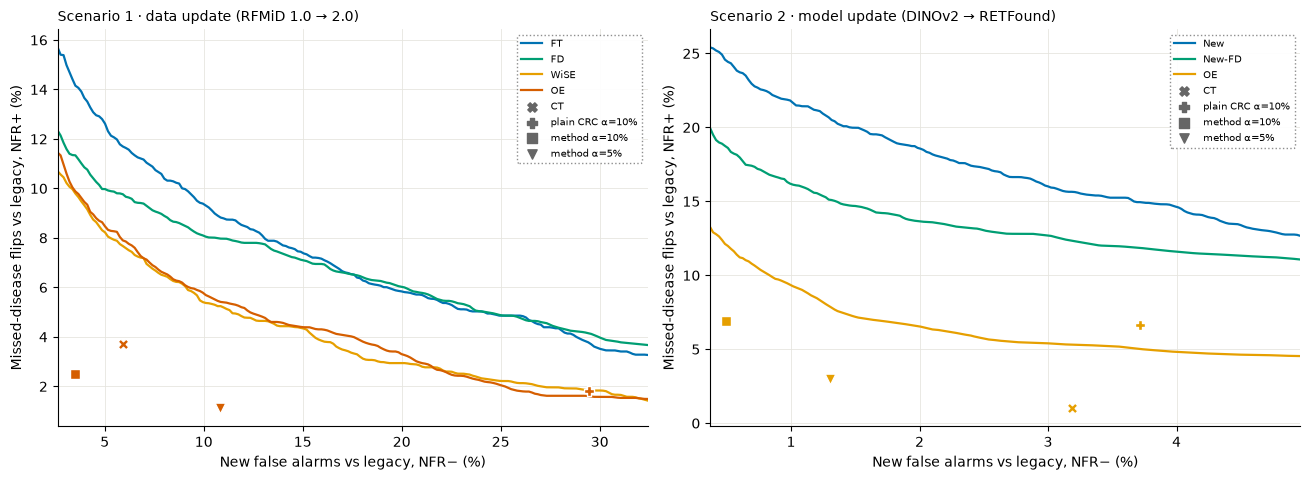

In [13]:
OI = ["#0072B2", "#009E73", "#E69F00", "#D55E00", "#CC79A7", "#56B4E9", "#000000"]   # Okabe-Ito
MARK = {"+CRCu-A10": ("P", "plain CRC α=10%"), "+CRCu10": ("P", "plain CRC α=10%"), "+CRC-L5": ("v", "method α=5%"), "+CRC5": ("v", "method α=5%"), "+CT": ("X", "CT"), "+CRC-A10": ("D", "certified α=10%, notebook 06"), "+CRC-L10": ("s", "method α=10%"),
        "+CRCg-L10": ("^", "certified α=10%, anchored + cost-aware"), "+CRC10": ("s", "method α=10%"),
        "+CRCg10": ("^", "certified α=10%, cost-aware")}

def panel(ax, FS, curves, mean, bases, suffixes, seeds, title):
    colors = dict(zip(curves, OI))
    pts = [f"{b}{s}" for b in bases for s in suffixes if f"{b}{s}" in mean.index]
    xs_all = [mean.loc[p, "NFR-_%"] for p in pts] + [mean.loc[c, "NFR-_%"] for c in curves]
    lo, hi = 0.75 * min(xs_all), 1.1 * max(xs_all)
    xs = np.linspace(lo, hi, 200)
    for c in curves:
        cs = [frontier.curve(FS[(c, s)], GRID) for s in seeds]
        ax.plot(xs, np.mean([[frontier.frontier_at(*cc, v) for v in xs] for cc in cs], axis=0), color=colors[c], lw=1.6, label=c)
    for p in pts:
        b, s = p.split("+")[0], "+" + p.split("+", 1)[1]
        ax.scatter(mean.loc[p, "NFR-_%"], mean.loc[p, "NFR+_%"], marker=MARK[s][0], s=60, color=colors[b], edgecolor="white", lw=1, zorder=5)
    for s in suffixes:
        ax.scatter([], [], marker=MARK[s][0], color="#666666", s=45, label=MARK[s][1])
    ax.set_xlim(lo, hi)
    ax.set_xlabel("New false alarms vs legacy, NFR− (%)")
    ax.set_ylabel("Missed-disease flips vs legacy, NFR+ (%)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(color="#e6e5df", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    leg = ax.legend(fontsize=7.5, loc="best", frameon=True, framealpha=0.95)
    leg.get_frame().set_linestyle(":")
    leg.get_frame().set_edgecolor("#888888")

panels = [p for p in ("s1", "s2") if (p == "s1" and RUN_S1) or (p == "s2" and RUN_S2)]
if panels:
    fig, axes = plt.subplots(1, len(panels), figsize=(6.6 * len(panels), 4.9), squeeze=False)
    for ax, p in zip(axes[0], panels):
        if p == "s1":
            panel(ax, FS1, CURVES1, mean1, ["OE"], ["+CT", "+CRCu-A10", "+CRC-L10", "+CRC-L5"], SEEDS,
                  "Scenario 1 · data update (RFMiD 1.0 → 2.0)")
        else:
            panel(ax, FS2, CURVES2, mean2, ["OE"], ["+CT", "+CRCu10", "+CRC10", "+CRC5"], SEEDS,
                  "Scenario 2 · model update (DINOv2 → RETFound)")
    fig.tight_layout()
    fig.savefig(RES / ("main08_frontier_quick.png" if QUICK else "main08_frontier.png"), dpi=200)
    plt.show()

## 12. Pre-registered criteria and verdict

In [14]:
H = {}
def alpha_of(name):
    return int("".join(ch for ch in name.split("+")[1] if ch.isdigit()))
if RUN_S1 and RUN_S2:
    a1_s1 = {m: bool(cx1[f"{m}10: CT vs F1 shape, anchored (CRC-L - CRCu-L)"][2] < 0) for m in ["FT", "WiSE", "OE"]}
    a1_s2 = {m: bool(cx2[f"{m}10: CT vs F1 shape (CRC - CRCu)"][2] < 0) for m in CURVES2}
    H["A1_CT_constraint_matters"] = bool(sum(a1_s1.values()) >= 2 and sum(a1_s2.values()) >= 2)
    H["A1_detail"] = {"s1": a1_s1, "s2": a1_s2}
    a2 = {m: bool(cx1[f"{m}10: method vs plain CRC (CRC-L - CRCu-A)"][2] < 0) for m in ["FT", "WiSE", "OE"]}
    H["A2_beats_plain_CRC"] = bool(sum(a2.values()) >= 2)
    H["A2_detail"] = a2
    k1, k2 = f"MAIN {OURS1[0]} vs FD", f"MAIN {OURS2[0]} vs New-FD"
    a3 = {"s1": bool(cy1[k1][2] < 0 and cx1[k1][2] < NI_MARGIN), "s2": bool(cy2[k2][2] < 0 and cx2[k2][2] < NI_MARGIN)}
    H["A3_beats_focal_distillation"] = bool(all(a3.values()))
    H["A3_detail"] = {"s1": {"d_NFR+": cy1[k1], "d_NFR-": cx1[k1]}, "s2": {"d_NFR+": cy2[k2], "d_NFR-": cx2[k2]}}
    cert = {**{("s1", n): float(mean1.loc[n, "img_risk_%"]) for n in NAMES1 if "+CRC" in n},
            **{("s2", n): float(mean2.loc[n, "img_risk_%"]) for n in NAMES2 if "+CRC" in n}}
    H["A4_certificates_hold"] = bool(all(r <= alpha_of(n) + 0.5 for (_, n), r in cert.items()))
    H["A4_worst"] = max(cert.items(), key=lambda kv: kv[1] - alpha_of(kv[0][1]))[0]
    H["legacy_vs_update_mAP_shared"] = {"s1": {m: round(float(mean1.loc[m, "mAP_shared"]), 4) for m in ["Legacy"] + BASES},
                                        "s2": {m: round(float(mean2.loc[m, "mAP_shared"]), 4) for m in ["Legacy"] + CURVES2}}
    H["s2_update_is_upgrade"] = bool(mean2.loc["New", "mAP_shared"] > mean2.loc["Legacy", "mAP_shared"])
    if not H["A4_certificates_hold"]:
        verdict = "REVISE (a certificate exceeded its alpha)"
    elif H["A2_beats_plain_CRC"] and H["A3_beats_focal_distillation"]:
        verdict = "CONFIRMED-FULL" if H["A1_CT_constraint_matters"] else "CONFIRMED-ANCHOR"
    else:
        verdict = "REVIEW"
else:
    verdict = "INCOMPLETE (run both scenarios)"

def compact(mean, sd, names):
    out = {}
    for n in names:
        r, s = mean.loc[n], sd.loc[n]
        out[n] = {"mAPsh": round(float(r["mAP_shared"]), 3), "mAP": round(float(r["mAP_all"]), 3),
                  "NFR+": [round(float(r["NFR+_%"]), 2), round(float(s["NFR+_%"]), 2)],
                  "NFR-": [round(float(r["NFR-_%"]), 2), round(float(s["NFR-_%"]), 2)],
                  "risk": round(float(r["img_risk_%"]), 2), "regr": round(float(r[KEYS8[-1]]), 2)}
    return out
def vcompact(v):
    return {n: [round(float(r["infeasible_share"]), 2), round(float(r["runs_above_alpha"]), 2), round(float(r["mean_n_cal"]), 1)]
            for n, r in v.iterrows()}
send = {"notebook": "08_confirm_and_main_tables", "quick_mode": QUICK, "seeds": SEEDS, "n_boot": CFG["n_boot"],
        "validity_format": "[infeasible share, runs above alpha, mean calibration images]", "means_format": "NFR as [mean, sd over seeds]"}
if RUN_S1:
    send["s1"] = {"means": compact(mean1, sd1, NAMES1), "gap": gap1, "d_NFR-": cx1, "d_NFR+": cy1, "validity": vcompact(valid1)}
if RUN_S2:
    send["s2"] = {"means": compact(mean2, sd2, NAMES2), "gap": gap2, "d_NFR-": cx2, "d_NFR+": cy2, "validity": vcompact(valid2)}
send["per_class"], send["hypotheses"], send["verdict"] = PC, H, verdict
(RES / ("main08_summary_quick.json" if QUICK else "main08_summary.json")).write_text(json.dumps(send, indent=1, default=str))
print("=" * 30, "SEND THIS BACK", "=" * 30)
print(json.dumps(send, default=str))

============================== SEND THIS BACK ==============================
{"notebook": "08_confirm_and_main_tables", "quick_mode": false, "seeds": [0, 1, 2], "n_boot": 300, "validity_format": "[infeasible share, runs above alpha, mean calibration images]", "means_format": "NFR as [mean, sd over seeds]", "s1": {"means": {"Legacy": {"mAPsh": 0.183, "mAP": 0.143, "NFR+": [0.0, 0.0], "NFR-": [0.0, 0.0], "risk": 0.0, "regr": 0.0}, "FD": {"mAPsh": 0.362, "mAP": 0.359, "NFR+": [9.59, 1.17], "NFR-": [6.21, 0.22], "risk": 30.32, "regr": 0.33}, "FD+CRC-A10": {"mAPsh": 0.362, "mAP": 0.359, "NFR+": [2.26, 0.27], "NFR-": [42.34, 5.18], "risk": 7.36, "regr": 0.33}, "FD+CRC-A5": {"mAPsh": 0.362, "mAP": 0.359, "NFR+": [0.68, 0.32], "NFR-": [69.6, 4.72], "risk": 2.01, "regr": 0.33}, "FD+CRC-L10": {"mAPsh": 0.362, "mAP": 0.359, "NFR+": [2.34, 0.32], "NFR-": [15.2, 9.01], "risk": 7.19, "regr": 0.33}, "FD+CRC-L5": {"mAPsh": 0.362, "mAP": 0.359, "NFR+": [1.19, 0.48], "NFR-": [31.11, 15.33], "risk": 3.38